# geosplat: photos ➜ orthophoto, point cloud, Gaussian splat

<a href="https://colab.research.google.com/github/GeomaticsCaminosUPM/geosplat/blob/main/examples/run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Turns a folder of photos into a **fast orthophoto**, a **point cloud**, a **Gaussian splat** and a **true
orthophoto + DSM**. If the photos have GPS, everything is read from their metadata (positions, UTM zone) and shown
on Google maps; a `name,x,y,z` CSV in the photo folder is used as ground control points. Without GPS, everything
except the maps still runs. Step-by-step tutorial: [docs/tutorial_notebook.md](https://github.com/GeomaticsCaminosUPM/geosplat/blob/main/docs/tutorial_notebook.md).

**Use:** pick a GPU runtime (*Runtime ▸ Change runtime type ▸ GPU*), set the 3 options in section 2, then
*Runtime ▸ Run all*.

## 1. Setup

Installs or refreshes `geosplat` (your local clone if the notebook is inside one, otherwise GitHub) and checks that
every stage runs on the GPU. On Colab, gsplat's CUDA code comes from a prebuilt wheel when one matches the runtime;
otherwise it is compiled once per session (3–5 min).

In [2]:
import importlib, shutil, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/GeomaticsCaminosUPM/geosplat.git"

# Install / refresh geosplat: your local clone if this notebook is inside one, otherwise GitHub.
root = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / "src" / "geosplat").is_dir()), None)
source = ["-e", str(root)] if root else [f"geosplat @ git+{REPO_URL}"]
pip = ["uv", "pip", "install", "--python", sys.executable] if shutil.which("uv") else [sys.executable, "-m", "pip", "install"]
subprocess.run(pip + ["-q", *source, "ipyleaflet"], check=True)                      # dependencies (first time)
subprocess.run(pip + ["-q", "--force-reinstall", "--no-deps", *source], check=True)   # latest geosplat code
for name in [m for m in sys.modules if m.split(".")[0] == "geosplat"]:
    del sys.modules[name]                                                             # reload it in this kernel
importlib.invalidate_caches()

import geosplat
gpu = geosplat.notebook.setup()   # Colab extras, prebuilt gsplat wheel, GPU check

geosplat 1.0.0 from /home/miguel/Documents/Proyectos/GaussianSplatting/src/geosplat (code modified 2026-11-19 09:34) | working dir: /home/miguel/Documents/Proyectos/GaussianSplatting


2026-11-19 13:42:19,264 Checking gsplat CUDA backend (first run compiles kernels, may take minutes)...


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
  GPU   torch (training, orthophotos)
  GPU   COLMAP (features, matching, BA)
  GPU   gsplat rasterizer


## 2. Options

| Option | Meaning |
|---|---|
| `IMAGES_DIR` | Your photos: a **`.zip`** (e.g. `"/content/images.zip"`, extracted automatically) or a folder. Subfolders (several flights), **videos** (frames are extracted) and GCP / positions files anywhere inside are used; folders named `ignore` or `results` are skipped. Or a sample name: `"seneca"` (drone, GPS), `"south_building"` (hand-held, no GPS) or `"aerial_gcps"` (survey with positions file and GCPs), downloaded into `examples/`. **Any file names work.** Photo positions are read from the photos' GPS or, if present, from a positions file next to them (ODM `geo.txt`, CSV with photo names, `.gpkg`/`.geojson`, DJI `.MRK`, `.gpx`, XMP sidecars). |
| `OUTPUT_DIR` | Where results go. `None`: `output_<PRESET>` inside the dataset folder (or next to a folder called `images`). |
| `PRESET` | Speed/quality, see below. |
| `TARGETS_ORTO` | Subfolder whose photos build a **full-resolution orthophoto to locate the targets** (e.g. a nadir flight flown with the targets), e.g. `"flight_targets"`. Only its GCP files are used. `None`: all photos and all GCP files. The fast and final orthophotos always use every photo. |
| `GCPS_CRS` | Coordinate system of a ground-control-point **CSV** next to the photos, e.g. `"EPSG:25830"`. `None`: inferred from the photo positions. Not needed for `.gpkg` / `.geojson` / `.shp` files (they include it). |

| `PRESET` | Time on Colab* | Use it for |
|---|---|---|
| `very_fast` | ~2 min | check that everything works |
| `fast` | ~5 min | previews |
| `medium` | ~25 min | good results (default) |
| `quality` | ~1.5 h | final products |

\*Estimated for 50 photos on a Colab T4 GPU, plus ~5–8 min of one-time setup per session (install + CUDA
build). A local RTX 4060 is about 2× faster.

In [3]:
IMAGES_DIR = "seneca"      # your photos: "/content/images.zip", a folder, or a sample: "seneca" | "south_building" | "aerial_gcps"
OUTPUT_DIR = None          # None -> next to the photos, in output_<PRESET>
PRESET = "fast"            # "very_fast" | "fast" | "medium" | "quality"
TARGETS_ORTO = None        # subfolder for the targets orthophoto, e.g. "flight_targets" (None: all photos)
GCPS_CRS = None            # CRS of a GCP CSV, e.g. "EPSG:25830" (None: inferred; not needed for .gpkg/.geojson/.shp)

from geosplat import datasets
IMAGES_DIR = datasets.prepare_images(IMAGES_DIR)          # downloads a sample / extracts a .zip if needed
dataset_dir = IMAGES_DIR.parent if IMAGES_DIR.name == "images" else IMAGES_DIR
OUTPUT_DIR = Path(OUTPUT_DIR) if OUTPUT_DIR else dataset_dir / f"output_{PRESET}"
sfm_cfg, train_cfg, geo_cfg = geosplat.make_configs(PRESET, geo={"gcps_crs": GCPS_CRS, "targets_orto": TARGETS_ORTO})
dataset = geosplat.sources.scan_dataset(IMAGES_DIR)          # photos in all subfolders, videos, side files
photos = dataset.photos
positions = geosplat.sources.photo_positions_in(IMAGES_DIR, geo_cfg)   # EXIF GPS, sidecars, geo.txt/CSV/GPX/MRK...
n_gps = len(positions)
GEO = n_gps >= 3
sources = sorted({p.source for p in positions.values()})
print(dataset.summary())
print(f"{n_gps} photos with a position ({', '.join(sources) or 'none'})"
      f" -> {'georeferenced mode' if GEO else 'local mode (no maps)'}")
print("outputs ->", OUTPUT_DIR)

40 photos, 0 with GPS -> local mode (no maps)
outputs -> examples/south_building/output_very_fast


## 3. Photos

With GPS, the map shows each photo: ■ straight down, camera symbol = oblique (cone toward the view), ● no direction
data. All photos are included (pink) by default. **Optional:** choose *Include* or *Exclude* and draw a polygon or
rectangle (toolbar, left) to apply it to the photos inside; click a photo to toggle it, or use the buttons. Excluded
photos are grey. Then run the next cell.

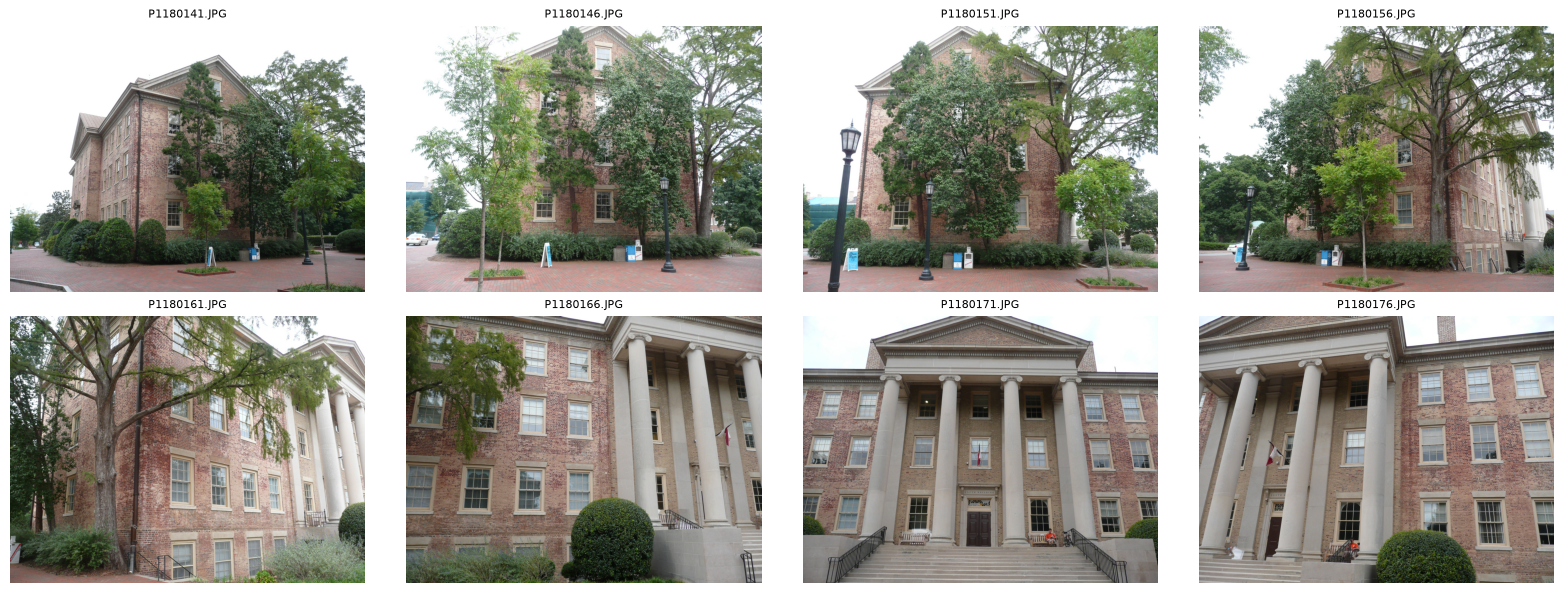

In [4]:
from geosplat import plots

selector = plots.photos(IMAGES_DIR, selection_file=OUTPUT_DIR / "selection.txt")   # None without GPS

## 4. Camera poses (COLMAP)

Runs on the GPU and is cached in `OUTPUT_DIR/colmap/`. Only the photos included on the map are used.

In [5]:
import time
from geosplat.geo import local_georeference
from geosplat.pipeline import prepare_scene

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if selector is not None and not selector.all_selected:
    sfm_cfg.image_list = selector.selected_names
    print(f"Using {len(selector.selected)} of {len(selector.photos)} photos")

timings = {}
t = time.time()
colmap_dir = geosplat.run_sfm(IMAGES_DIR, OUTPUT_DIR / "colmap", sfm_cfg)
gcp_file, gcp_crs = geosplat.geo.gcp_setup(IMAGES_DIR, geo_cfg) if GEO else (None, None)   # GCP file(s) + CRS
scene, geo = prepare_scene(colmap_dir, IMAGES_DIR, geo_cfg)
timings["colmap"] = time.time() - t
geo_gps = geo                                     # georeference from photo GPS (kept for the GCP step)
frame = geo or local_georeference(scene)          # map frame for orthophotos (local if no GPS)
gcp_pts = geosplat.geo.load_gcps(gcp_file, geo.crs, gcp_crs) if geo and gcp_file else None   # in the output CRS
if geo:
    geo.save(OUTPUT_DIR / "geo.json")
print(f"{len(scene.cameras)} cameras, {len(scene.points)} points, {timings['colmap']:.0f} s"
      + (f" | {geo.crs}, GPS fit {geo.rmse:.1f} m" if geo else "")
      + (f" | GCPs: {', '.join(sorted(gcp_pts))} ({gcp_crs or 'CRS unknown'})" if gcp_pts else ""))

2026-11-19 13:42:47,385 Reusing existing SfM result in examples/south_building/output_very_fast/colmap/undistorted


2026-11-19 13:42:47,629 Georeferencing skipped: 0 cameras with GPS


40 cameras, 8081 points, 0 s


## 5. Fast orthophoto

Seconds after COLMAP. Built on the sparse points: flat ground is right, while tall objects lean.

2026-11-19 13:42:49,047 Orthophoto GSD raised to 0.001 m to stay under 30000000 pixels
2026-11-19 13:42:49,049 fast_orto grid 5187x5788 at 0.001 m/px


examples/south_building/output_very_fast/fast_orto/fast_orto.tif (0.001 units/px)


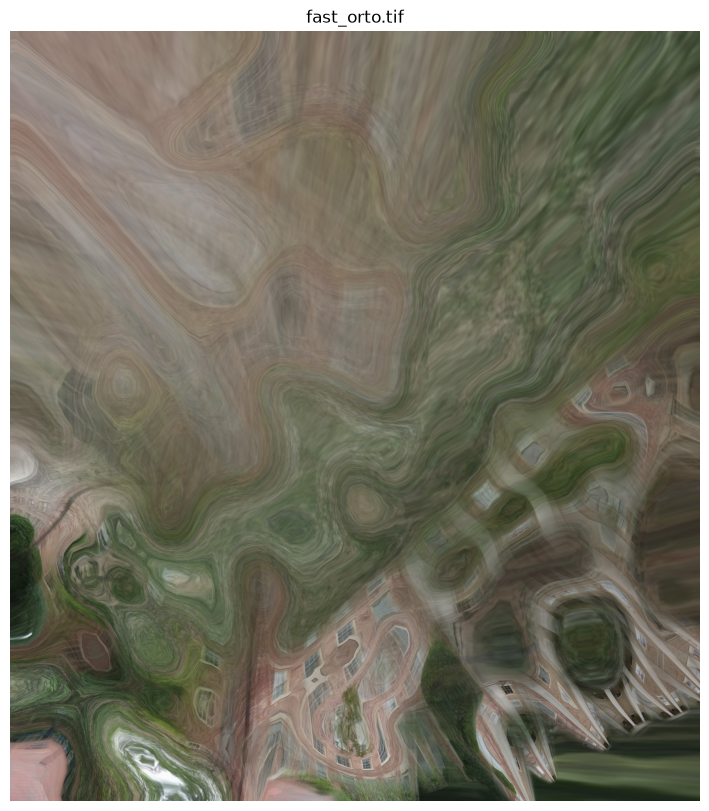

In [6]:
t = time.time()
fast = geosplat.make_fast_orthophoto(scene, frame, OUTPUT_DIR / "fast_orto", gcps=gcp_pts)
timings["fast_orto"] = time.time() - t
print(fast["fast_orto"], f"({fast['gsd']:.3f} units/px)")
plots.ortho(fast["fast_orto"], gcps=gcp_pts)

## 6. Gaussian splat (training)

The progress bar shows the loss and the number of Gaussians (`n`).

In [7]:
t = time.time()
result = geosplat.Trainer(scene, OUTPUT_DIR, train_cfg).train()
timings["train"] = time.time() - t
print(result.metrics)

2026-11-19 13:43:26,505 Checking gsplat CUDA backend (first run compiles kernels, may take minutes)...
2026-11-19 13:43:26,508 Training on cuda with the gsplat backend


2026-11-19 13:43:27,084 35 training / 5 test images
2026-11-19 13:43:27,149 Added 16644 background-sphere points at radius 13.07
2026-11-19 13:43:27,411 Initialized 24725 Gaussians


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-19 13:43:41,384 Saved examples/south_building/output_very_fast/splat.ply | {'psnr': 18.644434064344694, 'ssim': 0.5579108953475952, 'eval_split': 'test', 'num_gaussians': 42282, 'train_seconds': 10.91829514503479, 'steps': 1000}


{'psnr': 18.644434064344694, 'ssim': 0.5579108953475952, 'eval_split': 'test', 'num_gaussians': 42282, 'train_seconds': 10.91829514503479, 'steps': 1000}


## 7. Ground control points (optional)

Only with GPS photos and a ground-control-point file next to them (any file name; it is detected automatically): a `.gpkg` / `.geojson` / `.shp` with a CRS, or a `name,x,y,z` CSV (header optional; CRS set with `GCPS_CRS` or inferred). The map shows the true orthophoto (with `TARGETS_ORTO`: a full-resolution orthophoto of that folder only).
Choose a point and **click its target** to place a pink ✕; do this for at least 3 points. Drag a ✕ to move it, or
use the buttons to delete or clear. Then run the next cell and the ones after it; the final products then use the
GCP georeference. Without picks, the photo GPS is used.

Picks are saved to `OUTPUT_DIR/targets/located_targets.json`; `examples/run.py` on the same output folder applies them too.

In [8]:
picker = None
if GEO and gcp_pts:
    from geosplat.gcp import GCPPicker
    if TARGETS_ORTO:   # full-resolution orthophoto of the targets flight only
        ortho_gps = geosplat.ortho.make_targets_orthophoto(
            scene, geo_gps, colmap_dir.parent, geosplat.sources.resolve_subfolder(IMAGES_DIR, TARGETS_ORTO),
            OUTPUT_DIR / "targets" / "ortho_gps", result.params, result.sh_degree, gcps=gcp_pts)
        pick_tif, pick_dsm = ortho_gps["targets_orto"], ortho_gps["targets_dsm"]
    else:
        ortho_gps = geosplat.make_orthophoto(result.params, scene, geo_gps, OUTPUT_DIR / "targets" / "ortho_gps",
                                             result.sh_degree, gcps=gcp_pts)
        pick_tif, pick_dsm = ortho_gps["orthophoto"], ortho_gps["dsm"]
    picker = GCPPicker(pick_tif, gcp_pts, picks_file=OUTPUT_DIR / "targets" / "located_targets.json", geo=geo_gps, dsm_tif=pick_dsm)
    display(picker)
else:
    print("Skipped: needs GPS photos and a GCP file (.csv/.gpkg/.geojson/.shp) in", IMAGES_DIR)

Skipped: needs GPS photos and a GCP CSV in examples/south_building/images


In [9]:
geo = geo_gps                                     # re-running is safe: always start from the GPS georeference
if picker is not None and picker.picks:
    from geosplat.gcp import refine_georeference
    geo, report = refine_georeference(geo_gps, picker.picks, gcp_pts, pick_dsm)
    geo_gps.save(OUTPUT_DIR / "targets" / "geo_gps.json")
    print(f"{report['method']} from {report['points']} points | RMSE xy {report['rmse_xy_m']:.3f} m, "
          f"z {report['rmse_z_m']:.3f} m | scale change {report['scale_change']:.5f}")
    print("residuals (m):", report["residuals_m"])
elif picker is not None:
    print("No points placed: using the photo GPS. Place points above, then run this cell and the next ones.")
frame = geo or local_georeference(scene)
if geo:
    geo.save(OUTPUT_DIR / "geo.json")

## 8. Final products

The fast orthophoto, true orthophoto + DSM and point clouds are written with the final georeference (GCPs if
placed, otherwise GPS). The true orthophoto reprojects the photos onto the splat surface with occlusion checks, so
walls and trees stand upright.

In [10]:
t = time.time()
fast = geosplat.make_fast_orthophoto(scene, frame, OUTPUT_DIR / "fast_orto", gcps=gcp_pts)
ortho = geosplat.make_orthophoto(result.params, scene, frame, OUTPUT_DIR / "ortho", result.sh_degree, gcps=gcp_pts)
clouds = geosplat.export_point_clouds(result.params, scene, OUTPUT_DIR, geo,
                                      min_opacity=geo_cfg.dense_min_opacity)   # "auto" or e.g. 0.5
geosplat.save_viewer(result.params, OUTPUT_DIR / "viewer.html", result.train_cameras)
timings["products"] = time.time() - t
print(ortho["orthophoto"], "|", ortho["dsm"], "|", clouds["points_dense"])
if "gcp_dz" in ortho:
    print("DSM minus GCP height (m):", {k: round(v, 2) for k, v in ortho["gcp_dz"].items()})

2026-11-19 13:43:49,486 Orthophoto GSD raised to 0.001 m to stay under 30000000 pixels
2026-11-19 13:43:49,487 fast_orto grid 5187x5788 at 0.001 m/px
2026-11-19 13:43:58,267 Orthophoto GSD raised to 0.001 m to stay under 30000000 pixels
2026-11-19 13:43:58,269 Orthophoto grid 5187x5788 at 0.001 m/px
2026-11-19 13:44:05,994 Dense point cloud: automatic opacity threshold 0.46


examples/south_building/output_very_fast/ortho/orthophoto.tif | examples/south_building/output_very_fast/ortho/dsm.tif | examples/south_building/output_very_fast/points_dense.ply


## 9. Results

### Gaussian splat / point cloud (buttons at the top left; drag: orbit, right-drag: pan, wheel: zoom)

In [11]:
plots.splat(result.params, result.train_cameras, scene=scene, min_opacity=geo_cfg.dense_min_opacity, geo=geo)

/home/miguel/Documents/Proyectos/GaussianSplatting/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Point cloud

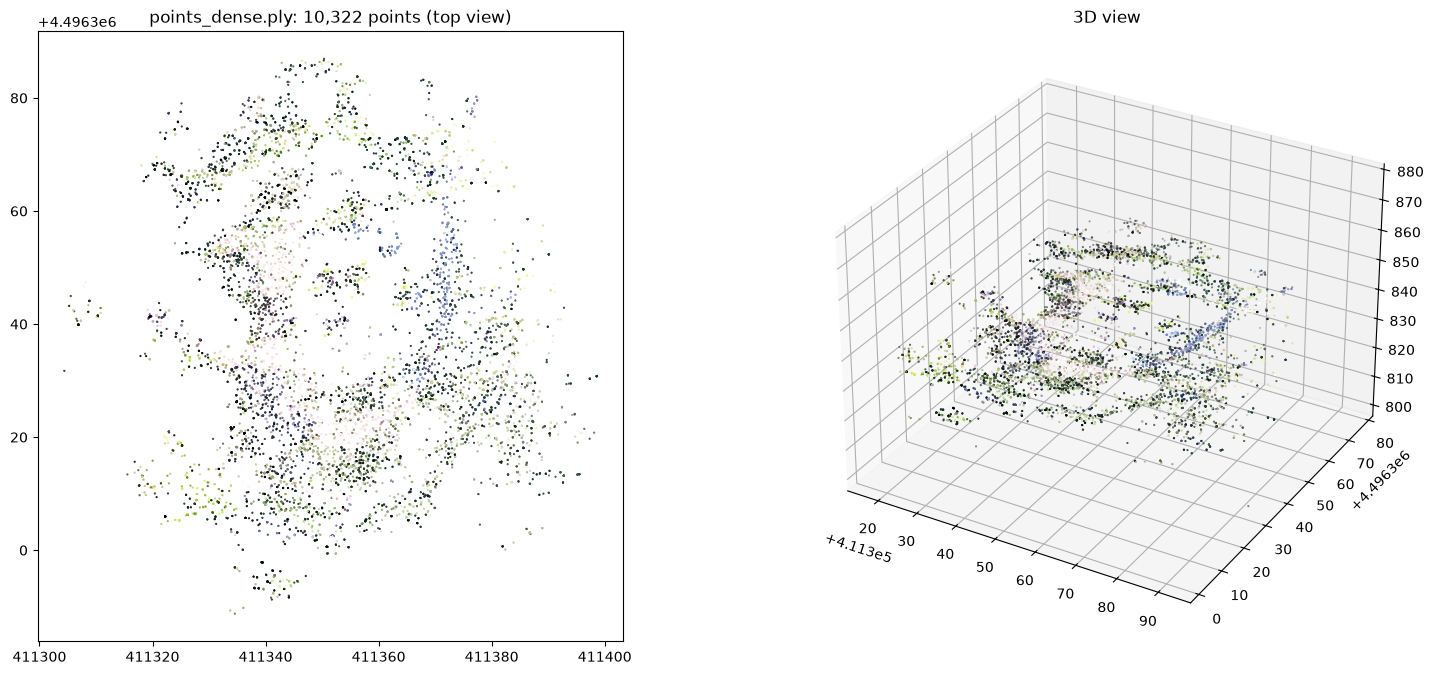

In [12]:
plots.point_cloud(clouds["points_dense"])

### True orthophoto

In [13]:
plots.ortho(ortho["orthophoto"], gcps=gcp_pts)

## 10. Output files

| File in `OUTPUT_DIR` | What it is | Open with |
|---|---|---|
| `fast_orto/fast_orto.tif` | first orthophoto (GeoTIFF) | QGIS |
| `ortho/orthophoto.tif`, `ortho/dsm.tif` | true orthophoto, surface model | QGIS |
| `points_sparse.ply`, `points_dense.ply` | colored point clouds | CloudCompare |
| `splat.ply` | Gaussian splat | [SuperSplat](https://superspl.at/editor) |
| `viewer.html` | interactive splat viewer | any browser |
| `geo.json`, `metrics.json`, `timings.json` | georeference, quality, times | text editor |
| `targets/located_targets.json`, `targets/geo_gps.json`, `targets/ortho_gps/` | GCP picks, GPS-only georeference and the orthophoto used to pick (section 7) | text editor / QGIS |

With GPS, rasters and point clouds use real coordinates (auto UTM zone). Without GPS they are in a local frame.
The next cell zips the results (without `colmap/`) and downloads them on Colab.

In [14]:
import json, shutil, zipfile

timings["total"] = sum(timings.values())
(OUTPUT_DIR / "timings.json").write_text(json.dumps(timings, indent=2))
print({k: round(v) for k, v in timings.items()}, "seconds")

zip_path = OUTPUT_DIR.with_suffix(".zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in OUTPUT_DIR.rglob("*"):
        if f.is_file() and "colmap" not in f.relative_to(OUTPUT_DIR).parts:
            zf.write(f, f.relative_to(OUTPUT_DIR))
print(zip_path, f"{zip_path.stat().st_size / 1e6:.0f} MB")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

{'colmap': 0, 'fast_orto': 3, 'train': 14, 'products': 3, 'total': 21} seconds
examples/drone2024/output_very_fast.zip 65 MB
